In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import accuracy_score, classification_report
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LinearRegression

# --- Configuration ---
TARGET_COLUMN = 'Recommended_Future_Focus'
COLUMNS_TO_DROP = [
    'Unnamed: 0.1', 'Unnamed: 0', 'Unnamed: 33', 'Unnamed: 34',
    'What are the skills do you have ?', 
    'What is you interested area?',      
    'Predicted_Strength_Area', 
    'CGPA_Improvement_Action'   
]

# 1. Data Loading & Cleaning
df = pd.read_csv("IUBAT_Student_Performance_Dataset_Final.csv")
df = df.drop(columns=[col for col in COLUMNS_TO_DROP if col in df.columns], errors='ignore')

# Handling Missing Values
for col in df.columns:
    if df[col].dtype == 'object':
        df[col] = df[col].fillna(df[col].mode()[0])
    else:
        df[col] = df[col].fillna(df[col].median())

# 2. Encoding
le_target = LabelEncoder()
df[TARGET_COLUMN] = le_target.fit_transform(df[TARGET_COLUMN].astype(str))

for col in df.select_dtypes(include=['object']).columns:
    if col != TARGET_COLUMN:
        le = LabelEncoder()
        df[col] = le.fit_transform(df[col].astype(str))

# 3. Data Splitting & Scaling
X = df.drop(columns=[TARGET_COLUMN])
y = df[TARGET_COLUMN].values

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 4. Model Training & Evaluation
models = {
    'Random Forest Classifier': RandomForestClassifier(n_estimators=100, random_state=42),
    'Decision Tree Classifier': DecisionTreeClassifier(random_state=42),
    'K-Nearest Neighbors': KNeighborsClassifier(n_neighbors=5),
    'Gaussian Naive Bayes': GaussianNB(),
    'Linear Regression': LinearRegression()
}

results = {}
preds_store = {}

for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    
    if name == 'Linear Regression':
        raw_preds = model.predict(X_test_scaled)
        y_pred = np.clip(np.rint(raw_preds).astype(int), 0, len(le_target.classes_) - 1)
    else:
        y_pred = model.predict(X_test_scaled)
    
    results[name] = accuracy_score(y_test, y_pred)
    preds_store[name] = y_pred


print("\nRecommended Future Focus Prediction")
print("----------------------------------")

print("Model Accuracy:")
for name, acc in results.items():
    print(f"{name}: {acc:.4f}")

# Best model
best_model = max(results.items(), key=lambda x: x[1])
best_model_name = best_model[0]
best_preds = preds_store[best_model_name]

print("\nBest Model:", best_model_name)
print("----------------------------------")

print("Classification Report:\n")
print(classification_report(
    le_target.inverse_transform(y_test),
    le_target.inverse_transform(best_preds),
    zero_division=0
))



Recommended Future Focus Prediction
----------------------------------
Model Accuracy:
Random Forest Classifier: 0.8715
Decision Tree Classifier: 0.8492
K-Nearest Neighbors: 0.4637
Gaussian Naive Bayes: 0.3240
Linear Regression: 0.0782

Best Model: Random Forest Classifier
----------------------------------
Classification Report:

                                                                                                              precision    recall  f1-score   support

Advanced projects in the predicted strength area and prepare for industrial certifications (e.g., AWS/CCNA).       0.96      1.00      0.98        64
                         Build a comprehensive portfolio, explore freelancing, and digital marketing trends.       0.00      0.00      0.00         1
 Build a strong professional portfolio (e.g., design/data science projects) and explore industry internship.       0.00      0.00      0.00         2
           Continue skill development and look for opportunities 

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import accuracy_score, classification_report
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LinearRegression

# 1. Setup & Data Loading
TARGET = 'Predicted_Strength_Area'
DROP_COLS = ['Unnamed: 0.1', 'Unnamed: 0', 'Unnamed: 33', 'Unnamed: 34',
             'What are the skills do you have ?', 'What is you interested area?',
             'Recommended_Future_Focus', 'CGPA_Improvement_Action']

df = pd.read_csv("IUBAT_Student_Performance_Dataset_Final.csv")
df = df.drop(columns=[c for c in DROP_COLS if c in df.columns], errors='ignore')

# 2. Cleaning & Encoding
for col in df.columns:
    df[col] = df[col].fillna(df[col].mode()[0] if df[col].dtype == 'object' else df[col].median())

le = LabelEncoder()
df[TARGET] = le.fit_transform(df[TARGET].astype(str))

for col in df.select_dtypes(include=['object']).columns:
    df[col] = LabelEncoder().fit_transform(df[col].astype(str))

# 3. Splitting & Scaling
X = df.drop(columns=[TARGET])
y = df[TARGET].values
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# 4. Model Training
models = {
    'Random Forest': RandomForestClassifier(random_state=42),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'KNN': KNeighborsClassifier(),
    'Naive Bayes': GaussianNB(),
    'Linear Regression': LinearRegression()
}

results = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    preds = model.predict(X_test)

    if name == 'Linear Regression':
        preds = np.clip(np.rint(preds).astype(int), 0, len(le.classes_) - 1)

    acc = accuracy_score(y_test, preds)
    results[name] = [acc, preds]


print("\nPredicted Strength Report")
print("--------------------------")

print("Model Accuracy:")
for name, metric in results.items():
    print(f"{name}: {metric[0]:.4f}")

# Find best model
best_model = max(results.items(), key=lambda x: x[1][0])
best_name = best_model[0]
best_preds = best_model[1][1]

print("\nBest Model:", best_name)
print("--------------------------")

print("Classification Report:\n")
print(classification_report(
    le.inverse_transform(y_test),
    le.inverse_transform(best_preds),
    zero_division=0
))



Predicted Strength Report
--------------------------
Model Accuracy:
Random Forest: 0.7989
Decision Tree: 0.6927
KNN: 0.5475
Naive Bayes: 0.0615
Linear Regression: 0.1788

Best Model: Random Forest
--------------------------
Classification Report:

                                          precision    recall  f1-score   support

                    Creative & Marketing       0.00      0.00      0.00         1
                    Foundational/General       0.00      0.00      0.00         2
  High Performance: Creative & Marketing       0.00      0.00      0.00         1
  High Performance: Foundational/General       0.00      0.00      0.00         1
 High Performance: Networking & Security       0.43      0.25      0.32        12
High Performance: Software & Development       0.82      0.92      0.87        53
                   Networking & Security       0.80      0.35      0.48        23
                 Other Specialized Skill       0.00      0.00      0.00         1
           

In [11]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import accuracy_score, classification_report
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LinearRegression 

# Target column
TARGET_COLUMN = 'CGPA_Improvement_Action'

# Columns to drop
COLUMNS_TO_DROP = [
    'Unnamed: 0.1', 'Unnamed: 0', 'Unnamed: 33', 'Unnamed: 34',
    'What are the skills do you have ?', 
    'What is you interested area?',      
    'Predicted_Strength_Area', 
    'Recommended_Future_Focus'   
]

# 1. Data loading and preprocessing
df = pd.read_csv("IUBAT_Student_Performance_Dataset_Final.csv")
df = df.drop(columns=[col for col in COLUMNS_TO_DROP if col != TARGET_COLUMN], errors='ignore')

# Handle missing values
for col in df.columns:
    if df[col].dtype == 'object':
        df[col] = df[col].fillna(df[col].mode()[0])
    elif df[col].dtype in ['int64', 'float64']:
        df[col] = df[col].fillna(df[col].median())

# Encode categorical data
categorical_cols = df.select_dtypes(include=['object']).columns.tolist()
le_target = LabelEncoder()
df[TARGET_COLUMN] = le_target.fit_transform(df[TARGET_COLUMN])

for col in categorical_cols:
    if col != TARGET_COLUMN:
        le = LabelEncoder()
        df[col] = df[col].astype(str)
        df[col] = le.fit_transform(df[col])

# 2. Train-test split and scaling
X = df.drop(columns=[TARGET_COLUMN])
y = df[TARGET_COLUMN].astype(int)
y = np.ravel(y)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

scaler = StandardScaler()
X_train_final = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 3. Initialize models
classifiers = {
    'RandomForestClassifier (RF)': RandomForestClassifier(random_state=42),
    'DecisionTreeClassifier (DT)': DecisionTreeClassifier(random_state=42),
    'KNeighborsClassifier (KNN)': KNeighborsClassifier(n_neighbors=5),
    'GaussianNB (Naive Bayes)': GaussianNB(),
    'LinearRegression (LR)': LinearRegression() 
}

# 4. Train and evaluate models
results = {}
pred_store = {}

for name, model in classifiers.items():
    model.fit(X_train_final, y_train)
    
    if name == 'LinearRegression (LR)':
        y_pred_float = model.predict(X_test_scaled)
        y_pred = np.round(y_pred_float).astype(int)
    else:
        y_pred = model.predict(X_test_scaled)
        
    acc = accuracy_score(y_test, y_pred)
    results[name] = acc
    pred_store[name] = y_pred

# 5. Simple output
print("\nCGPA Improvement Action Prediction")
print("----------------------------------")

print("Model Accuracy:")
for name, acc in results.items():
    print(f"{name}: {acc:.4f}")

# Select best model
best_model_name = max(results, key=results.get)
best_preds = pred_store[best_model_name]

print("\nBest Model:", best_model_name)
print("----------------------------------")

# Convert predictions back to original labels
y_test_original = le_target.inverse_transform(y_test)
valid_classes = le_target.classes_
y_pred_original = np.array([
    le_target.inverse_transform([p])[0] if p in range(len(valid_classes)) else 'Unknown'
    for p in best_preds
])

print("Classification Report:\n")
print(classification_report(y_test_original, y_pred_original, zero_division=0))



CGPA Improvement Action Prediction
----------------------------------
Model Accuracy:
RandomForestClassifier (RF): 0.9609
DecisionTreeClassifier (DT): 0.9441
KNeighborsClassifier (KNN): 0.5866
GaussianNB (Naive Bayes): 0.3352
LinearRegression (LR): 0.3296

Best Model: RandomForestClassifier (RF)
----------------------------------
Classification Report:

                                                                                                     precision    recall  f1-score   support

Focus on fundamental courses, increase daily study hours, and seek teacher consultancy immediately.       0.96      1.00      0.98        77
                Increase class attendance to 90%+ and review subject weaknesses with a peer mentor.       0.89      0.89      0.89         9
    Maintain academic focus and consider peer mentoring to reinforce concepts in advanced subjects.       1.00      1.00      1.00        36
 Prioritize difficult subjects in the study schedule and actively participate 


>>> Processing Target: Predicted_Strength_Area <<<
Accuracy for Predicted_Strength_Area: 79.89%
Confusion Matrix saved as: CM_Predicted_Strength_Area.png


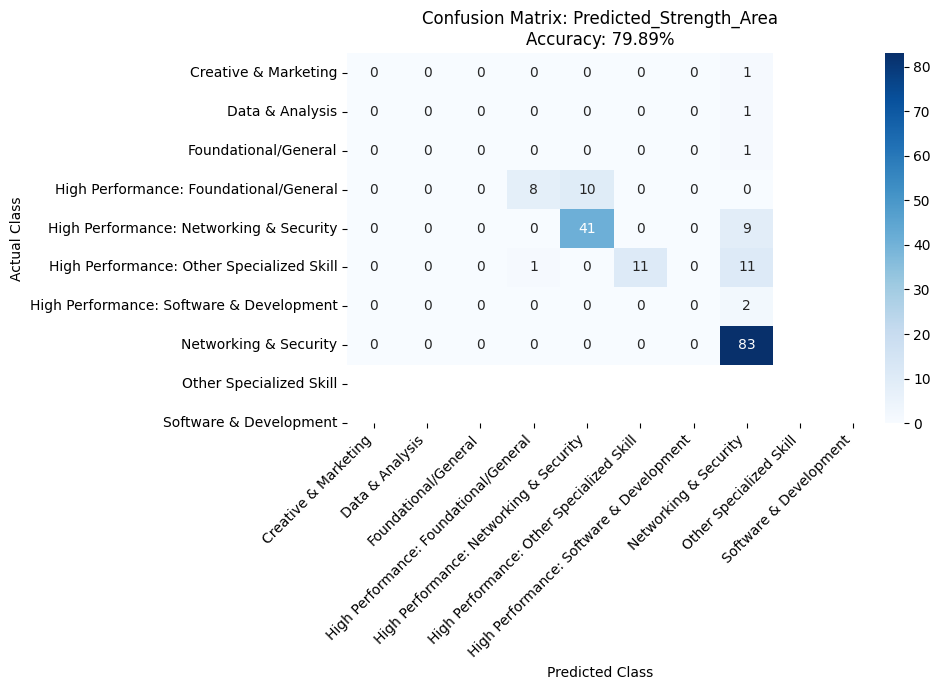

In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import confusion_matrix, accuracy_score
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier

# 1. Load the dataset
file_path = "IUBAT_Student_Performance_Dataset_Final.csv"
df = pd.read_csv(file_path)

# Define columns to drop (features that shouldn't be in X)
columns_to_drop = ['Unnamed: 0.1', 'Unnamed: 0', 'Unnamed: 33', 'Unnamed: 34',
                    'Predicted_Strength_Area', 'Recommended_Future_Focus', 'CGPA_Improvement_Action']

# Target variable for this run
target_name = 'Predicted_Strength_Area'

def process_and_plot_strength():
    print(f"\n>>> Processing Target: {target_name} <<<")
    
    # Handling missing values in target and removing single-sample classes for stratification
    df_temp = df.dropna(subset=[target_name]).copy()
    counts = df_temp[target_name].value_counts()
    valid_classes = counts[counts > 1].index
    df_temp = df_temp[df_temp[target_name].isin(valid_classes)]

    # Separate Features (X) and Target (y)
    X = df_temp.drop(columns=columns_to_drop, errors='ignore')
    y_raw = df_temp[target_name]
    
    # Convert categorical features to numeric (One-Hot Encoding)
    X = pd.get_dummies(X, drop_first=True)
    
    # Encode target labels
    le = LabelEncoder()
    y = le.fit_transform(y_raw.astype(str))
    class_names = le.classes_

    # Split data: 80% Training, 20% Testing
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42, stratify=y
    )

    # Impute missing values in features using median
    imputer = SimpleImputer(strategy='median')
    X_train = imputer.fit_transform(X_train)
    X_test = imputer.transform(X_test)

    # Initialize and train Random Forest Classifier
    model = RandomForestClassifier(n_estimators=200, max_depth=10, min_samples_leaf=5, random_state=42)
    model.fit(X_train, y_train)
    
    # Make predictions and calculate accuracy
    y_pred = model.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    
    print(f"Accuracy for {target_name}: {acc*100:.2f}%")

    # --- Generate Confusion Matrix ---
    cm = confusion_matrix(y_test, y_pred)
    
    # Visualization using Seaborn Heatmap
    plt.figure(figsize=(10, 7))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
                xticklabels=class_names, yticklabels=class_names)
    
    plt.title(f'Confusion Matrix: {target_name}\nAccuracy: {acc*100:.2f}%')
    plt.ylabel('Actual Class')
    plt.xlabel('Predicted Class')
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    
    # Save the figure
    file_name = f"CM_{target_name}.png"
    plt.savefig(file_name)
    print(f"Confusion Matrix saved as: {file_name}")
    plt.show()

# Run the function
if __name__ == "__main__":
    try:
        process_and_plot_strength()
    except Exception as e:
        print(f"An error occurred: {e}")


--- Model Report: Recommended_Future_Focus ---
| RandomForestClassifier (RF)    | Accuracy: 0.8715 |
| DecisionTreeClassifier (DT)    | Accuracy: 0.8492 |
| KNeighborsClassifier (KNN)     | Accuracy: 0.4637 |
| GaussianNB (Naive Bayes)       | Accuracy: 0.3240 |
| LinearRegression (LR)          | Accuracy: 0.0615 |


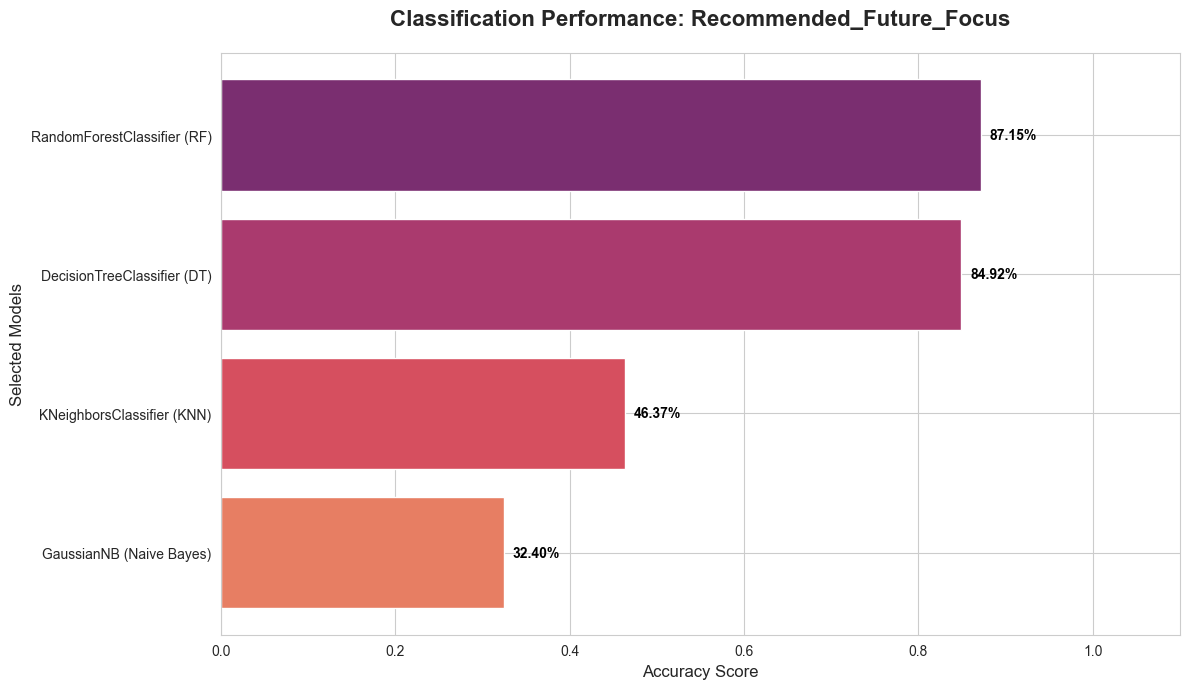

In [20]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import accuracy_score, classification_report
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LinearRegression 

# Target column
TARGET_COLUMN = 'Recommended_Future_Focus'

# Columns to be dropped
COLUMNS_TO_DROP = [
    'Unnamed: 0.1', 'Unnamed: 0', 'Unnamed: 33', 'Unnamed: 34',
    'What are the skills do you have ?', 
    'What is you interested area?',      
    'Predicted_Strength_Area', 
    'CGPA_Improvement_Action'   
]

# 1. Data Processing
df = pd.read_csv("IUBAT_Student_Performance_Dataset_Final.csv")
df = df.drop(columns=[col for col in COLUMNS_TO_DROP if col != TARGET_COLUMN], errors='ignore')

# Fill missing values
for col in df.columns:
    if df[col].dtype == 'object':
        df[col] = df[col].fillna(df[col].mode()[0])
    elif df[col].dtype in ['int64', 'float64']:
        df[col] = df[col].fillna(df[col].median())

# Handle categorical encoding
categorical_cols = df.select_dtypes(include=['object']).columns.tolist()
le_target = LabelEncoder()
df[TARGET_COLUMN] = le_target.fit_transform(df[TARGET_COLUMN])

for col in categorical_cols:
    if col != TARGET_COLUMN:
        le = LabelEncoder()
        df[col] = df[col].astype(str)
        df[col] = le.fit_transform(df[col])

# 2. Data Splitting and Scaling
X = df.drop(columns=[TARGET_COLUMN])
y = df[TARGET_COLUMN].astype(int) 
y = np.ravel(y) 

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
scaler = StandardScaler()
X_train_final = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 3. Model Initialization
classifiers = {
    'RandomForestClassifier (RF)': RandomForestClassifier(random_state=42),
    'DecisionTreeClassifier (DT)': DecisionTreeClassifier(random_state=42),
    'KNeighborsClassifier (KNN)': KNeighborsClassifier(n_neighbors=5),
    'GaussianNB (Naive Bayes)': GaussianNB(),
    'LinearRegression (LR)': LinearRegression() 
}

# 4. Model Training and Evaluation
results = {}
for name, model in classifiers.items():
    model.fit(X_train_final, y_train)
    
    if name == 'LinearRegression (LR)':
        y_pred_float = model.predict(X_test_scaled)
        y_pred = np.round(y_pred_float).astype(int)
    else:
        y_pred = model.predict(X_test_scaled)
        
    accuracy = accuracy_score(y_test, y_pred)
    results[name] = accuracy

# 5. Print Final Report
print(f"\n{'='*70}")
print(f"--- Model Report: {TARGET_COLUMN} ---")
print(f"{'='*70}")

# Sort and display results
sorted_results = sorted(results.items(), key=lambda item: item[1], reverse=True)
for name, acc in sorted_results:
    print(f"| {name:<30} | Accuracy: {acc:.4f} |")

# --- Visualization (Excluding Linear Regression) ---
# Filter results to exclude LR for classification plot
filtered_results = {name: acc for name, acc in results.items() if 'LinearRegression' not in name}
sorted_plot_data = sorted(filtered_results.items(), key=lambda x: x[1], reverse=True)
model_names, accuracy_scores = zip(*sorted_plot_data)

sns.set_style("whitegrid")
plt.figure(figsize=(12, 7))

# Plot styling using "flare_r" color palette
colors = sns.color_palette("flare_r", len(model_names))
bars = plt.barh(model_names, accuracy_scores, color=colors)

plt.title(f'Classification Performance: {TARGET_COLUMN}', fontsize=16, pad=20, fontweight='bold')
plt.xlabel('Accuracy Score', fontsize=12)
plt.ylabel('Selected Models', fontsize=12)
plt.xlim(0, 1.1)
plt.gca().invert_yaxis()

# Add percentage text labels on bars
for i, v in enumerate(accuracy_scores):
    plt.text(v + 0.01, i, f'{v*100:.2f}%', color='black', va='center', fontweight='bold')

plt.tight_layout()
plt.show()


--- Model Report: Predicted_Strength_Area ---
--- Final Accuracy Report ---
| RandomForestClassifier (RF)    | Accuracy: 0.7989 |
| DecisionTreeClassifier (DT)    | Accuracy: 0.6927 |
| KNeighborsClassifier (KNN)     | Accuracy: 0.5475 |
| LinearRegression (LR)          | Accuracy: 0.1564 |
| GaussianNB (Naive Bayes)       | Accuracy: 0.0615 |


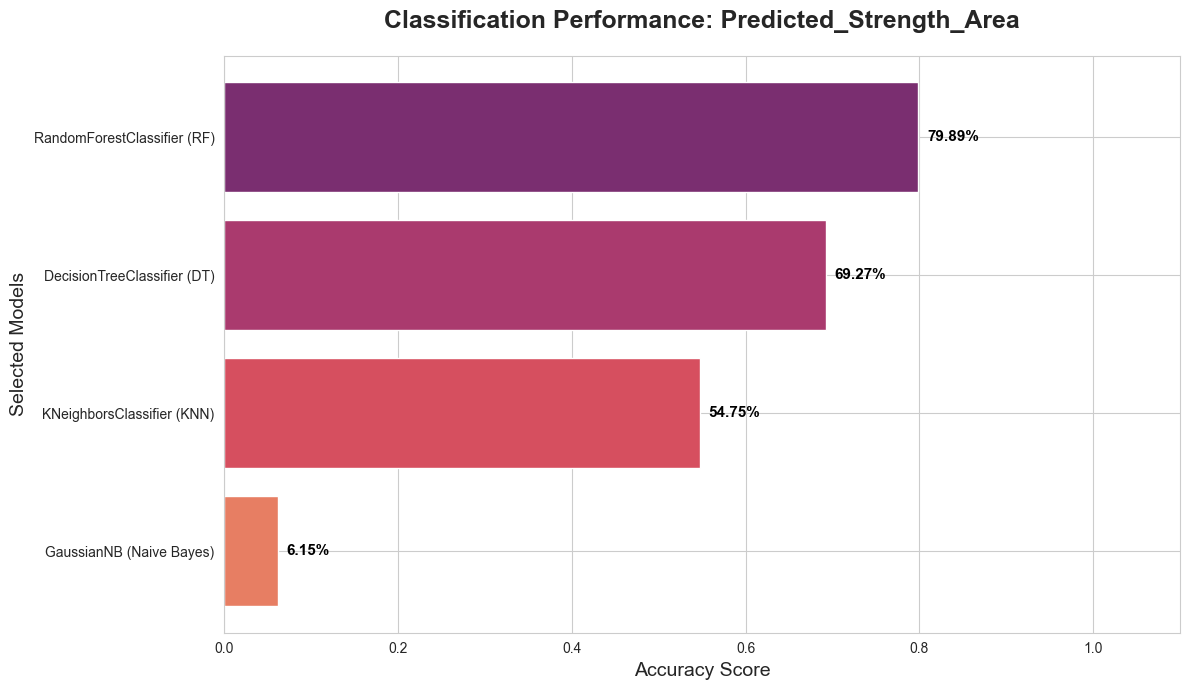


--- Best Model Detailed Report (RandomForestClassifier (RF)) ---
                                          precision    recall  f1-score   support

                    Creative & Marketing       0.00      0.00      0.00         1
                    Foundational/General       0.00      0.00      0.00         2
  High Performance: Creative & Marketing       0.00      0.00      0.00         1
  High Performance: Foundational/General       0.00      0.00      0.00         1
 High Performance: Networking & Security       0.43      0.25      0.32        12
High Performance: Software & Development       0.82      0.92      0.87        53
                   Networking & Security       0.80      0.35      0.48        23
                 Other Specialized Skill       0.00      0.00      0.00         1
                  Software & Development       0.81      0.98      0.89        85

                                accuracy                           0.80       179
                              

In [21]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import accuracy_score, classification_report
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LinearRegression 

# Target column
TARGET_COLUMN = 'Predicted_Strength_Area'

# Columns to be dropped from features
COLUMNS_TO_DROP = [
    'Unnamed: 0.1', 'Unnamed: 0', 'Unnamed: 33', 'Unnamed: 34',
    'What are the skills do you have ?', 
    'What is you interested area?',      
    'Recommended_Future_Focus', 
    'CGPA_Improvement_Action'   
]

# 1. Data Processing
df = pd.read_csv("IUBAT_Student_Performance_Dataset_Final.csv")

# Drop specified columns while ensuring target column is handled correctly
df = df.drop(columns=[col for col in COLUMNS_TO_DROP if col != TARGET_COLUMN], errors='ignore')

# Fill missing values: Mode for categorical and Median for numerical data
for col in df.columns:
    if df[col].dtype == 'object':
        df[col] = df[col].fillna(df[col].mode()[0])
    elif df[col].dtype in ['int64', 'float64']:
        df[col] = df[col].fillna(df[col].median())

# Label Encoding for categorical features
categorical_cols = df.select_dtypes(include=['object']).columns.tolist()
le_target = LabelEncoder()
df[TARGET_COLUMN] = le_target.fit_transform(df[TARGET_COLUMN])

for col in categorical_cols:
    if col != TARGET_COLUMN:
        le = LabelEncoder()
        df[col] = df[col].astype(str)
        df[col] = le.fit_transform(df[col])

# 2. Data Splitting and Scaling
X = df.drop(columns=[TARGET_COLUMN])
y = df[TARGET_COLUMN].astype(int) 
y = np.ravel(y) 

# Split into Training (80%) and Testing (20%) sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Standardize features
scaler = StandardScaler()
X_train_final = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 3. Model Initialization
classifiers = {
    'RandomForestClassifier (RF)': RandomForestClassifier(random_state=42),
    'DecisionTreeClassifier (DT)': DecisionTreeClassifier(random_state=42),
    'KNeighborsClassifier (KNN)': KNeighborsClassifier(n_neighbors=5),
    'GaussianNB (Naive Bayes)': GaussianNB(),
    'LinearRegression (LR)': LinearRegression() 
}

# 4. Model Training and Evaluation
results = {}
for name, model in classifiers.items():
    model.fit(X_train_final, y_train)
    
    # Logic for Linear Regression: round continuous output to nearest integer class
    if name == 'LinearRegression (LR)':
        y_pred_float = model.predict(X_test_scaled)
        y_pred = np.round(y_pred_float).astype(int)
    else:
        y_pred = model.predict(X_test_scaled)
        
    accuracy = accuracy_score(y_test, y_pred)
    results[name] = accuracy

# 5. Print Final Report
print(f"\n{'='*70}")
print(f"--- Model Report: {TARGET_COLUMN} ---")
print(f"{'='*70}")
print("--- Final Accuracy Report ---")

# Display results sorted by accuracy
sorted_results = sorted(results.items(), key=lambda item: item[1], reverse=True)
for name, acc in sorted_results:
    print(f"| {name:<30} | Accuracy: {acc:.4f} |")

# --- Visualization (Excluding Linear Regression) ---
# Filtering out LR to keep the plot consistent with classification metrics
filtered_results = {name: acc for name, acc in results.items() if 'LinearRegression' not in name}
sorted_plot_data = sorted(filtered_results.items(), key=lambda x: x[1], reverse=True)
model_names, accuracy_scores = zip(*sorted_plot_data)

sns.set_style("whitegrid")
plt.figure(figsize=(12, 7))

# Set color palette (flare_r style)
colors = sns.color_palette("flare_r", len(model_names))
bars = plt.barh(model_names, accuracy_scores, color=colors)

plt.title(f'Classification Performance: {TARGET_COLUMN}', fontsize=18, pad=20, fontweight='bold')
plt.xlabel('Accuracy Score', fontsize=14)
plt.ylabel('Selected Models', fontsize=14)
plt.xlim(0, 1.1)
plt.gca().invert_yaxis()

# Add accuracy percentage labels on the bars
for i, v in enumerate(accuracy_scores):
    plt.text(v + 0.01, i, f'{v*100:.2f}%', color='black', va='center', fontweight='bold', fontsize=11)

plt.tight_layout()
plt.show()

# Print Detailed Report for the Best Model
best_model_name = sorted_results[0][0]
print(f"\n--- Best Model Detailed Report ({best_model_name}) ---")
best_model = classifiers[best_model_name]

if best_model_name == 'LinearRegression (LR)':
    y_pred_best = np.round(best_model.predict(X_test_scaled)).astype(int)
else:
    y_pred_best = best_model.predict(X_test_scaled)

# Inverse transform to show original labels in the report
y_test_orig = le_target.inverse_transform(y_test)
# Handle potential out-of-bounds predictions for Linear Regression
y_pred_orig = [le_target.inverse_transform([p])[0] if p in range(len(le_target.classes_)) else "Unknown" for p in y_pred_best]

print(classification_report(y_test_orig, y_pred_orig, zero_division=0))
print(f"{'='*70}\n")


CGPA Improvement Action Prediction
----------------------------------
Model Accuracy:
RandomForestClassifier (RF): 0.9609
DecisionTreeClassifier (DT): 0.9441
KNeighborsClassifier (KNN): 0.5866
GaussianNB (Naive Bayes): 0.3352
LinearRegression (LR): 0.3296


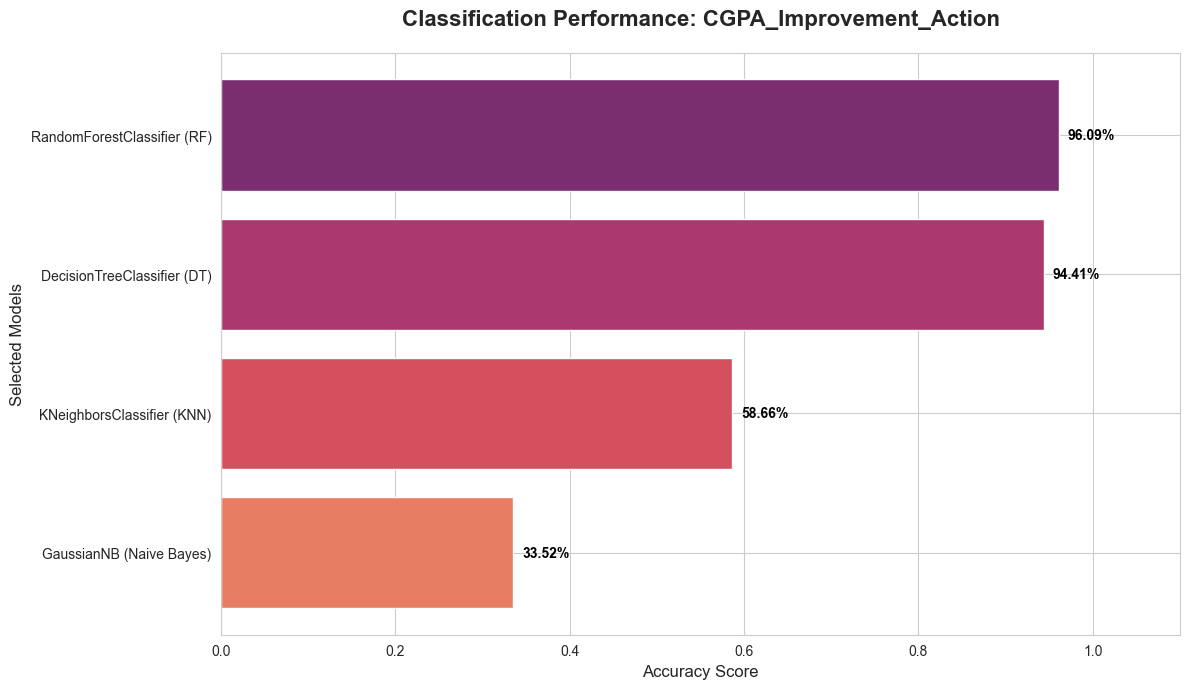


Best Model: RandomForestClassifier (RF)
----------------------------------
Classification Report:

                                                                                                     precision    recall  f1-score   support

Focus on fundamental courses, increase daily study hours, and seek teacher consultancy immediately.       0.96      1.00      0.98        77
                Increase class attendance to 90%+ and review subject weaknesses with a peer mentor.       0.89      0.89      0.89         9
    Maintain academic focus and consider peer mentoring to reinforce concepts in advanced subjects.       1.00      1.00      1.00        36
 Prioritize difficult subjects in the study schedule and actively participate in class discussions.       0.94      1.00      0.97        48
                                 Regularly track CGPA and make necessary adjustments to study plan.       1.00      0.33      0.50         9

                                                    

In [22]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import accuracy_score, classification_report
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LinearRegression 

# Target column
TARGET_COLUMN = 'CGPA_Improvement_Action'

# Columns to drop
COLUMNS_TO_DROP = [
    'Unnamed: 0.1', 'Unnamed: 0', 'Unnamed: 33', 'Unnamed: 34',
    'What are the skills do you have ?', 
    'What is you interested area?',      
    'Predicted_Strength_Area', 
    'Recommended_Future_Focus'   
]

# 1. Data loading and preprocessing
df = pd.read_csv("IUBAT_Student_Performance_Dataset_Final.csv")
df = df.drop(columns=[col for col in COLUMNS_TO_DROP if col != TARGET_COLUMN], errors='ignore')

# Handle missing values
for col in df.columns:
    if df[col].dtype == 'object':
        df[col] = df[col].fillna(df[col].mode()[0])
    elif df[col].dtype in ['int64', 'float64']:
        df[col] = df[col].fillna(df[col].median())

# Encode categorical data
categorical_cols = df.select_dtypes(include=['object']).columns.tolist()
le_target = LabelEncoder()
df[TARGET_COLUMN] = le_target.fit_transform(df[TARGET_COLUMN])

for col in categorical_cols:
    if col != TARGET_COLUMN:
        le = LabelEncoder()
        df[col] = df[col].astype(str)
        df[col] = le.fit_transform(df[col])

# 2. Train-test split and scaling
X = df.drop(columns=[TARGET_COLUMN])
y = df[TARGET_COLUMN].astype(int)
y = np.ravel(y)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

scaler = StandardScaler()
X_train_final = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 3. Initialize models
classifiers = {
    'RandomForestClassifier (RF)': RandomForestClassifier(random_state=42),
    'DecisionTreeClassifier (DT)': DecisionTreeClassifier(random_state=42),
    'KNeighborsClassifier (KNN)': KNeighborsClassifier(n_neighbors=5),
    'GaussianNB (Naive Bayes)': GaussianNB(),
    'LinearRegression (LR)': LinearRegression() 
}

# 4. Train and evaluate models
results = {}
pred_store = {}

for name, model in classifiers.items():
    model.fit(X_train_final, y_train)
    
    if name == 'LinearRegression (LR)':
        y_pred_float = model.predict(X_test_scaled)
        y_pred = np.round(y_pred_float).astype(int)
    else:
        y_pred = model.predict(X_test_scaled)
        
    acc = accuracy_score(y_test, y_pred)
    results[name] = acc
    pred_store[name] = y_pred

# 5. Output results
print("\nCGPA Improvement Action Prediction")
print("----------------------------------")

print("Model Accuracy:")
for name, acc in results.items():
    print(f"{name}: {acc:.4f}")

# --- 6. Visualization (Excluding Linear Regression) ---
# Filter results to exclude LR for the classification plot
filtered_results = {name: acc for name, acc in results.items() if 'LinearRegression' not in name}
sorted_plot_data = sorted(filtered_results.items(), key=lambda x: x[1], reverse=True)
model_names, accuracy_scores = zip(*sorted_plot_data)

sns.set_style("whitegrid")
plt.figure(figsize=(12, 7))

# Plot styling using "flare_r" color palette
colors = sns.color_palette("flare_r", len(model_names))
plt.barh(model_names, accuracy_scores, color=colors)

plt.title(f'Classification Performance: {TARGET_COLUMN}', fontsize=16, pad=20, fontweight='bold')
plt.xlabel('Accuracy Score', fontsize=12)
plt.ylabel('Selected Models', fontsize=12)
plt.xlim(0, 1.1)
plt.gca().invert_yaxis()

# Add percentage text labels on bars
for i, v in enumerate(accuracy_scores):
    plt.text(v + 0.01, i, f'{v*100:.2f}%', color='black', va='center', fontweight='bold')

plt.tight_layout()
plt.show()

# 7. Best Model Selection and Detailed Report
best_model_name = max(results, key=results.get)
best_preds = pred_store[best_model_name]

print("\nBest Model:", best_model_name)
print("----------------------------------")

# Convert predictions back to original labels
y_test_original = le_target.inverse_transform(y_test)
valid_classes = le_target.classes_
y_pred_original = np.array([
    le_target.inverse_transform([p])[0] if p in range(len(valid_classes)) else 'Unknown'
    for p in best_preds
])

print("Classification Report:\n")
print(classification_report(y_test_original, y_pred_original, zero_division=0))